# California House Price Prediction — repeated K-fold model comparison
Capstone notebook (NIELIT Ropar × IIT Ropar AI & ML programme; industry training with KFPN). Data: **California Housing**
(1990 U.S. census, 20,640 block groups), from R. Kelley Pace & Ronald Barry (1997), *Sparse spatial autoregressions*,
Statistics & Probability Letters 33(3):291–297, via the StatLib repository and `sklearn.datasets.fetch_california_housing`.
Target `MedHouseVal` is in **$100,000** and is **top-coded at 5.00001 ($500k)**.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json, warnings
from sklearn.model_selection import RepeatedKFold, GroupKFold, cross_validate, train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.compose import TransformedTargetRegressor as TTR
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans
warnings.filterwarnings("ignore"); SEED = 42
df = pd.read_csv("data/california_housing.csv"); T = "MedHouseVal"; F = [c for c in df if c != T]; CAP = 5.0
X, y = df[F], df[T]; capped = (y >= CAP).to_numpy()
print(df.shape, "capped rows:", capped.sum(), f"({capped.mean():.1%})"); df.describe().T.round(2)

(20640, 9) capped rows: 992 (4.8%)


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
HouseAge,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
AveRooms,20640.0,5.43,2.47,0.85,4.44,5.23,6.05,141.91
AveBedrms,20640.0,1.10,0.47,0.33,1.01,1.05,1.10,34.07
Population,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
AveOccup,20640.0,3.07,10.39,0.69,2.43,2.82,3.28,1243.33
Latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
Longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
MedHouseVal,20640.0,2.07,1.15,0.15,1.20,1.80,2.65,5.00


## 1. EDA — note the spike at the $500k cap and the long tails of AveRooms / AveOccup

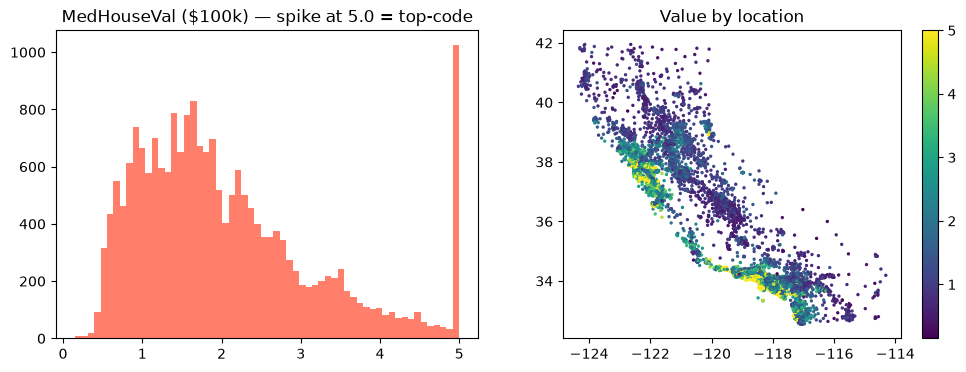

Latitude      -0.144160
AveBedrms     -0.046701
Longitude     -0.045967
Population    -0.024650
AveOccup      -0.023737
HouseAge       0.105623
AveRooms       0.151948
MedInc         0.688075
MedHouseVal    1.000000
Name: MedHouseVal, dtype: float64

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(y, bins=60, color="#ff7f6b"); ax[0].set_title("MedHouseVal ($100k) — spike at 5.0 = top-code")
s = ax[1].scatter(df.Longitude, df.Latitude, c=y, s=2, cmap="viridis"); plt.colorbar(s, ax=ax[1]); ax[1].set_title("Value by location")
plt.show(); df.corr()[T].sort_values()

## 2. Repeated K-fold comparison
`RepeatedKFold(n_splits=5, n_repeats=3)` = 15 folds (3 rather than 5 repeats to keep run time reasonable on 20k rows).
Predictions are clipped to the $500k cap before scoring (no real value is above it). Metrics in **$100k**.

In [3]:
def clipped(m): return lambda e, Xv, yv: m(np.minimum(e.predict(Xv), CAP), yv)
sc = {"rmse": clipped(lambda p, t: -np.sqrt(np.mean((p - t) ** 2))), "mae": clipped(lambda p, t: -np.mean(np.abs(p - t))),
      "r2": clipped(lambda p, t: 1 - np.sum((p - t) ** 2) / np.sum((t - t.mean()) ** 2))}
lg = dict(func=np.log, inverse_func=np.exp)
logf = FunctionTransformer(lambda Z: np.column_stack([np.log1p(np.clip(Z[:, :6], 0, None)), Z[:, 6:]]))
GBP = dict(n_estimators=400, learning_rate=0.1, max_depth=5, min_samples_leaf=20, subsample=0.8, random_state=SEED)
models = {
 "Mean baseline": DummyRegressor(),
 "Linear regression": make_pipeline(StandardScaler(), LinearRegression()),
 "Ridge": make_pipeline(StandardScaler(), Ridge(1.0)),
 "Ridge, log target + log features": TTR(make_pipeline(logf, StandardScaler(), Ridge(1.0)), **lg),
 "Random forest": RandomForestRegressor(200, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
 "HistGB, log target": TTR(HistGradientBoostingRegressor(max_iter=500, learning_rate=0.1, random_state=SEED), **lg),
 "GBR squared loss, log target": TTR(GradientBoostingRegressor(**GBP), **lg),
 "GBR Huber loss, log target (deployed)": TTR(GradientBoostingRegressor(loss="huber", **GBP), **lg),
}
cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED); rows = {}
for n, m in models.items():
    r = cross_validate(m, X.to_numpy(), y.to_numpy(), cv=cv, scoring=sc, n_jobs=-1)
    rows[n] = {k: (-r["test_" + k] if k != "r2" else r["test_r2"]) for k in sc}
tab = pd.DataFrame({n: {f"{k}": f"{v.mean():.3f} ± {v.std():.3f}" for k, v in d.items()} for n, d in rows.items()}).T
tab["rmse_mean"] = [rows[n]["rmse"].mean() for n in tab.index]; tab = tab.sort_values("rmse_mean"); print(tab.drop(columns="rmse_mean").to_markdown())
json.dump({n: {k: [float(v.mean()), float(v.std())] for k, v in d.items()} for n, d in rows.items()}, open("cv_results.json", "w"), indent=1)

|                                       | rmse          | mae           | r2             |
|:--------------------------------------|:--------------|:--------------|:---------------|
| GBR Huber loss, log target (deployed) | 0.461 ± 0.009 | 0.291 ± 0.005 | 0.840 ± 0.006  |
| HistGB, log target                    | 0.463 ± 0.011 | 0.294 ± 0.006 | 0.839 ± 0.008  |
| GBR squared loss, log target          | 0.467 ± 0.009 | 0.298 ± 0.005 | 0.836 ± 0.006  |
| Random forest                         | 0.501 ± 0.010 | 0.326 ± 0.006 | 0.811 ± 0.007  |
| Ridge, log target + log features      | 0.659 ± 0.011 | 0.453 ± 0.007 | 0.674 ± 0.011  |
| Linear regression                     | 0.861 ± 0.543 | 0.527 ± 0.014 | 0.214 ± 1.502  |
| Ridge                                 | 0.861 ± 0.543 | 0.527 ± 0.014 | 0.214 ± 1.502  |
| Mean baseline                         | 1.154 ± 0.013 | 0.912 ± 0.009 | -0.000 ± 0.000 |


## 3. Honesty checks
**3a. Spatial CV.** Random folds put neighbouring block groups in train and test, which flatters models that use
latitude/longitude. Here 50 KMeans clusters of (lat, lon) form groups, so whole areas are held out.

In [4]:
grp = KMeans(50, random_state=SEED, n_init=10).fit_predict(df[["Latitude", "Longitude"]])
for n in ["Ridge", "GBR Huber loss, log target (deployed)"]:
    r = cross_validate(models[n], X.to_numpy(), y.to_numpy(), cv=GroupKFold(5), groups=grp, scoring=sc, n_jobs=-1)
    print(f"{n}: spatial-CV RMSE {-r['test_rmse'].mean():.3f}, R² {r['test_r2'].mean():.3f}")

Ridge: spatial-CV RMSE 0.735, R² 0.572


GBR Huber loss, log target (deployed): spatial-CV RMSE 0.592, R² 0.721


**3b. The $500k cap.** 992 rows (4.8%) are top-coded. Their true values are unknown (≥ $500k), so (i) we report
errors on uncapped rows separately and (ii) test dropping capped rows from training.

In [5]:
Xtr, Xte, ytr, yte, ctr, cte = train_test_split(X, y, capped, test_size=0.2, random_state=SEED)
dep = models["GBR Huber loss, log target (deployed)"]
dep.fit(Xtr, ytr); p = np.minimum(dep.predict(Xte), CAP)
rm = lambda a, b: float(np.sqrt(np.mean((a - b) ** 2)))
print(f"hold-out RMSE all {rm(p, yte):.3f}, MAE {np.mean(abs(p-yte)):.3f}, R² {1-np.sum((p-yte)**2)/np.sum((yte-yte.mean())**2):.3f}")
print(f"hold-out RMSE uncapped rows {rm(p[~cte], yte[~cte]):.3f} | capped rows {rm(p[cte], yte[cte]):.3f}")
print(f"capped rows predicted ≥ $400k: {(p[cte] >= 4).mean():.1%}")
d2 = TTR(GradientBoostingRegressor(loss="huber", **GBP), **lg).fit(Xtr[~ctr], ytr[~ctr]); p2 = np.minimum(d2.predict(Xte), CAP)
print(f"trained WITHOUT capped rows -> RMSE uncapped {rm(p2[~cte], yte[~cte]):.3f}, capped {rm(p2[cte], yte[cte]):.3f}")

hold-out RMSE all 0.463, MAE 0.292, R² 0.837
hold-out RMSE uncapped rows 0.415 | capped rows 1.052
capped rows predicted ≥ $400k: 74.5%


trained WITHOUT capped rows -> RMSE uncapped 0.415, capped 1.166


**3c. Quantile range (5%–95%) coverage**, using the same smaller quantile models as the web app.

In [6]:
RP = dict(n_estimators=150, learning_rate=0.1, max_depth=4, min_samples_leaf=40, subsample=0.8, random_state=SEED)
lo = GradientBoostingRegressor(loss="quantile", alpha=0.05, **RP).fit(Xtr, np.log(ytr)); hi = GradientBoostingRegressor(loss="quantile", alpha=0.95, **RP).fit(Xtr, np.log(ytr))
L, H = np.minimum(np.exp(lo.predict(Xte)), CAP), np.minimum(np.exp(hi.predict(Xte)), CAP)
print(f"coverage {np.mean((yte >= L) & (yte <= H)):.3f}, median width ${np.median(H-L)*100:.0f}k")

coverage 0.848, median width $123k


## 4. Permutation importance (hold-out, 10 repeats, RMSE increase in $100k)

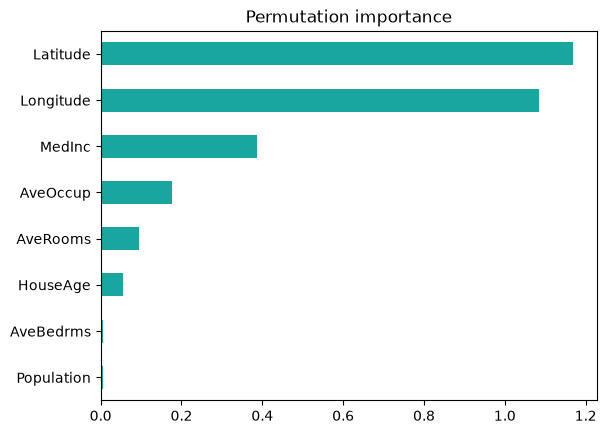

Latitude      1.169
Longitude     1.085
MedInc        0.386
AveOccup      0.176
AveRooms      0.094
HouseAge      0.055
AveBedrms     0.006
Population    0.006


In [7]:
pi = permutation_importance(dep, Xte, yte, scoring="neg_root_mean_squared_error", n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, F).sort_values(); imp.plot.barh(color="#1aa6a0", title="Permutation importance"); plt.show()
print(imp[::-1].round(3).to_string())

## 5. Conclusions
* Gradient boosting on a log target is clearly best; the Huber-loss version is deployed (near-identical accuracy, more robust).
* Location (lat/lon) and median income dominate. Spatial CV is harsher than random CV — the honest number for unseen areas.
* Values are 1990 dollars and capped at $500k: the model cannot predict above the cap, and the web app flags estimates near it.